<a href="https://colab.research.google.com/github/uuu4/bil485-mlp-mnist/blob/main/mlp_mnist.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BIL485 Derin Öğrenme — Ödev 1
## MNIST ile MLP Tabanlı El Yazısı Rakam Tanıma

**Amaç:** MNIST üzerinde sıfırdan bir Multi-Layer Perceptron (MLP) eğitmek, farklı yapılandırmaları karşılaştırmak ve modeli kendi el yazımla yazdığım okul numarası üzerinde sınamak.

**Ödev kuralları ve bu notebook'ta nasıl karşılandığı**

| Kural | Karşılığı |
|---|---|
| CNN yok, MLP var | Yalnızca `nn.Linear` + ReLU katmanları (`make_mlp`) |
| Hazır eğitilmiş model yok, sıfırdan eğitim | Ağırlıklar rastgele başlatılıp MNIST üzerinde eğitilir |
| Train / validation / test ayrımı açık | 60 000 eğitim görüntüsü → 50 000 train + 10 000 validation; 10 000 test ayrı tutulur |
| Test verisi geliştirmede kullanılmaz | Konfigürasyon seçimi **yalnızca validation** ile yapılır; test, en sonda (§5) bir kez ölçülür |
| Hiperparametreler raporlanır | Her deneyin ayarı tabloda ve §3'te listelenir |
| Kod çalıştırılabilir | Hücreler sırayla çalıştırılır (GPU varsa kullanılır, yoksa CPU); §6 için `my_digits/` hazır olmalı |

**Bölümler:** 1) Kurulum ve veri · 2) Deney 1: temel MLP · 3) Deney 2: hiperparametre karşılaştırması · 4) Seçim · 5) Final test · 6) Kendi el yazım · 7) Değerlendirme

**Colab için kurulum.** Notebook GitHub'dan Colab'de açıldığında `my_digits/` klasörü gelmez; bu hücre repoyu klonlayıp içine geçer. Yerelde repo klasöründen çalıştırılıyorsa hiçbir şey yapmaz.

In [ ]:
import os, subprocess, sys
REPO_URL = "https://github.com/uuu4/bil485-mlp-mnist"
if not os.path.exists("my_digits"):
    subprocess.run(["git", "clone", "-q", REPO_URL, "bil485-mlp-mnist"], check=True)
    os.chdir("bil485-mlp-mnist")
print("çalışma dizini:", os.getcwd(), "| my_digits:", sorted(os.listdir("my_digits"))[:3], "...")


çalışma dizini: /content/bil485-mlp-mnist | my_digits: ['01.png', '02.png', '03.png'] ...


## 1. Kurulum ve veri

In [ ]:
import os, time, random, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets
from PIL import Image

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("device:", device)

os.makedirs("results", exist_ok=True)
def savefig(name):
    plt.savefig(f"results/{name}.png", dpi=150, bbox_inches="tight")

device: cuda


**Veri bölünmesi.** MNIST'in resmi eğitim kümesi (60 000) rastgele 50 000 *train* ve 10 000 *validation* olarak ikiye ayrılır. Resmi test kümesi (10 000) ayrı tutulur; §5'e kadar hiçbir karar onunla verilmez.

Piksel değerleri `[0,1]`'e çekilir, sonra **yalnızca train kümesinin** ortalaması ve standart sapmasıyla standartlaştırılır (validation ve test'in istatistiği sızmasın diye).

In [ ]:
train_full = datasets.MNIST("data", train=True, download=True)
test_set   = datasets.MNIST("data", train=False, download=True)

X_full = train_full.data.float().div(255)          # (60000, 28, 28)
y_full = train_full.targets
X_test_raw = test_set.data.float().div(255)        # (10000, 28, 28)
y_test = test_set.targets

g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(X_full), generator=g)
train_idx, val_idx = perm[:50_000], perm[50_000:]

X_train_raw, y_train = X_full[train_idx], y_full[train_idx]
X_val_raw,   y_val   = X_full[val_idx],   y_full[val_idx]

MEAN, STD = X_train_raw.mean().item(), X_train_raw.std().item()   # sadece train'den
print(f"train piksel ortalaması={MEAN:.4f}, std={STD:.4f}")

def prep(X):                      # (N,28,28) -> standartlaştırılmış düz (N,784)
    return ((X - MEAN) / STD).reshape(len(X), -1)

X_train, X_val, X_test = prep(X_train_raw).to(device), prep(X_val_raw).to(device), prep(X_test_raw).to(device)
y_train, y_val, y_test = y_train.to(device), y_val.to(device), y_test.to(device)

print("train:", tuple(X_train.shape), "| val:", tuple(X_val.shape), "| test:", tuple(X_test.shape))

100%|██████████| 9.91M/9.91M [00:00<00:00, 20.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 503kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.64MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 3.63MB/s]


train piksel ortalaması=0.1307, std=0.3082
train: (50000, 784) | val: (10000, 784) | test: (10000, 784)


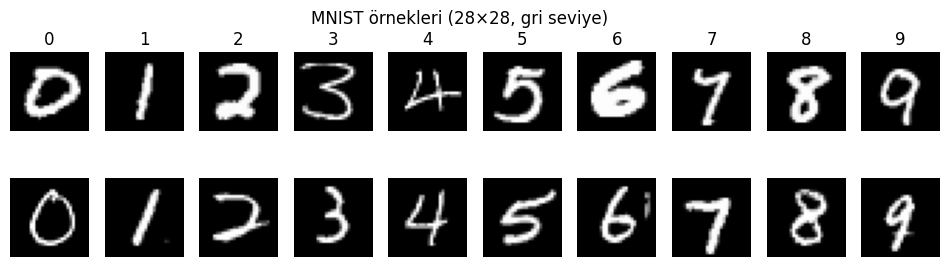

,train,val,test
sınıf,,,
0,4923,1000,980
1,5613,1129,1135
2,4958,1000,1032
3,5093,1038,1010
4,4863,979,982
5,4546,875,892
6,4933,985,958
7,5204,1061,1028
8,4882,969,974


In [ ]:
# Örnek görüntüler ve sınıf dağılımı
fig, axes = plt.subplots(2, 10, figsize=(12, 3))
for d in range(10):
    i = (y_train.cpu() == d).nonzero()[0].item()
    axes[0, d].imshow(X_train_raw[i], cmap="gray"); axes[0, d].set_title(str(d)); axes[0, d].axis("off")
    j = (y_train.cpu() == d).nonzero()[5].item()
    axes[1, d].imshow(X_train_raw[j], cmap="gray"); axes[1, d].axis("off")
plt.suptitle("MNIST örnekleri (28×28, gri seviye)")
savefig("mnist_ornekler"); plt.show()

dist = pd.DataFrame({
    "train": torch.bincount(y_train.cpu(), minlength=10).numpy(),
    "val":   torch.bincount(y_val.cpu(), minlength=10).numpy(),
    "test":  torch.bincount(y_test.cpu(), minlength=10).numpy(),
}); dist.index.name = "sınıf"
dist

### Model, eğitim ve değerlendirme yardımcıları

- **Model:** `784 → hidden… → 10`; her gizli katmanda `Linear + ReLU` (isteğe bağlı Dropout). Çıkış katmanında aktivasyon yok; softmax `CrossEntropyLoss` içinde.
- **Loss:** `CrossEntropyLoss` (10 sınıflı sınıflandırma için uygun kayıp).
- **Eğitim:** mini-batch; her epoch sonunda train ve validation kümelerinde loss/accuracy `eval` modunda ölçülür (Dropout kapalı). Eğitim süresi yalnızca ağırlık güncelleme döngüsünü kapsar (metrik hesapları hariç).
- Tüm deneylerde aynı tohum (`SEED`) kullanılır; böylece farklar yalnızca değiştirilen hiperparametreden gelir.

In [ ]:
def make_mlp(hidden=(256, 128), dropout=0.0):
    layers, d = [], 28 * 28
    for h in hidden:
        layers += [nn.Linear(d, h), nn.ReLU()]
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        d = h
    layers.append(nn.Linear(d, 10))
    return nn.Sequential(*layers)

@torch.no_grad()
def evaluate(model, X, y, bs=5000):
    model.eval()
    loss_sum, correct = 0.0, 0
    for i in range(0, len(X), bs):
        out = model(X[i:i + bs])
        loss_sum += F.cross_entropy(out, y[i:i + bs], reduction="sum").item()
        correct += (out.argmax(1) == y[i:i + bs]).sum().item()
    return loss_sum / len(X), correct / len(X)

def sync():
    if device.type == "cuda":
        torch.cuda.synchronize()

def train(cfg, epochs, verbose=False):
    torch.manual_seed(SEED)
    model = make_mlp(cfg["hidden"], cfg["dropout"]).to(device)
    if cfg["opt"] == "adam":
        opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    else:
        opt = torch.optim.SGD(model.parameters(), lr=cfg["lr"], momentum=0.9)

    hist = {k: [] for k in ["train_loss", "val_loss", "train_acc", "val_acc"]}
    train_time = 0.0
    bs = cfg["batch"]
    for ep in range(epochs):
        model.train()
        sync(); t0 = time.time()
        order = torch.randperm(len(X_train), device=device)
        for i in range(0, len(order), bs):
            idx = order[i:i + bs]
            loss = F.cross_entropy(model(X_train[idx]), y_train[idx])
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
        sync(); train_time += time.time() - t0

        tl, ta = evaluate(model, X_train, y_train)
        vl, va = evaluate(model, X_val, y_val)
        for k, v in zip(hist, [tl, vl, ta, va]):
            hist[k].append(v)
        if verbose:
            print(f"epoch {ep+1:2d}/{epochs} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f}")
    return {"cfg": cfg, "hist": hist, "time": train_time,
            "state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}}

def plot_hist(hist, title, fname):
    ep = range(1, len(hist["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(ep, hist["train_loss"], label="train"); ax[0].plot(ep, hist["val_loss"], label="validation")
    ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss"); ax[0].set_title("Loss"); ax[0].legend()
    ax[1].plot(ep, hist["train_acc"], label="train"); ax[1].plot(ep, hist["val_acc"], label="validation")
    ax[1].set_xlabel("epoch"); ax[1].set_ylabel("accuracy"); ax[1].set_title("Accuracy"); ax[1].legend()
    fig.suptitle(title); savefig(fname); plt.show()

## 2. Deney 1 — Temel MLP

| Hiperparametre | Değer |
|---|---|
| Mimari | 784 → 256 → 128 → 10 (2 gizli katman) |
| Aktivasyon | ReLU |
| Loss | CrossEntropyLoss |
| Optimizer | Adam, `lr = 1e-3` |
| Batch size | 128 |
| Epoch | 15 |
| Dropout | yok |

Bu bölümde **train/validation** sonuçları raporlanır. Test accuracy, ödev kuralı gereği (test verisi geliştirme sürecinde kullanılmamalı) §5'te, tüm seçimler bittikten sonra ölçülür ve oradaki tabloya eklenir.

epoch  1/15 | train loss 0.1287 acc 0.9617 | val loss 0.1571 acc 0.9515
epoch  2/15 | train loss 0.0782 acc 0.9778 | val loss 0.1179 acc 0.9635
epoch  3/15 | train loss 0.0488 acc 0.9857 | val loss 0.0944 acc 0.9704
epoch  4/15 | train loss 0.0356 acc 0.9893 | val loss 0.0923 acc 0.9719
epoch  5/15 | train loss 0.0309 acc 0.9902 | val loss 0.0962 acc 0.9703
epoch  6/15 | train loss 0.0206 acc 0.9935 | val loss 0.0882 acc 0.9745
epoch  7/15 | train loss 0.0203 acc 0.9937 | val loss 0.0914 acc 0.9738
epoch  8/15 | train loss 0.0136 acc 0.9959 | val loss 0.0860 acc 0.9748
epoch  9/15 | train loss 0.0222 acc 0.9921 | val loss 0.1080 acc 0.9725
epoch 10/15 | train loss 0.0199 acc 0.9932 | val loss 0.1113 acc 0.9741
epoch 11/15 | train loss 0.0099 acc 0.9970 | val loss 0.0937 acc 0.9765
epoch 12/15 | train loss 0.0091 acc 0.9966 | val loss 0.1142 acc 0.9752
epoch 13/15 | train loss 0.0103 acc 0.9966 | val loss 0.1178 acc 0.9758
epoch 14/15 | train loss 0.0132 acc 0.9956 | val loss 0.1215 acc

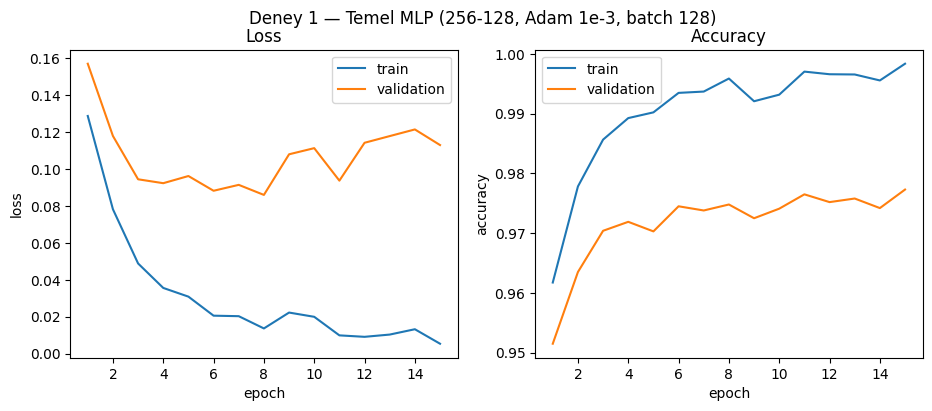

In [ ]:
EPOCHS = 15
BASE = dict(hidden=(256, 128), opt="adam", lr=1e-3, batch=128, dropout=0.0)

runs = {}
runs["baseline"] = train(BASE, EPOCHS, verbose=True)
plot_hist(runs["baseline"]["hist"], "Deney 1 — Temel MLP (256-128, Adam 1e-3, batch 128)", "deney1_egitim_egrileri")

In [ ]:
h = runs["baseline"]["hist"]
exp1 = pd.DataFrame({
    "Training loss": [h["train_loss"][-1]], "Validation loss": [h["val_loss"][-1]],
    "Training accuracy": [h["train_acc"][-1]], "Validation accuracy": [h["val_acc"][-1]],
    "Eğitim süresi (s)": [runs["baseline"]["time"]],
}, index=["Deney 1 (son epoch)"])
exp1.round(4)

,Training loss,Validation loss,Training accuracy,Validation accuracy,Eğitim süresi (s)
Deney 1 (son epoch),0.0054,0.113,0.9984,0.9773,8.8068


## 3. Deney 2 — Hiperparametre karşılaştırması

Temel modelden **her seferinde tek bir şeyi** değiştiriyorum; böylece farkın nedeni belli oluyor. Seçim ölçütü **validation accuracy**'dir (son epoch).

Eğitmeden önce yazdığım **hipotezler** (sonuçlarla §7'de karşılaştıracağım):

- **Öğrenme oranı:** çok büyük (`1e-2`, Adam) kararsızlık / daha yüksek loss, çok küçük (`1e-4`) aynı epoch sayısında yetersiz eğitim.
- **Batch size:** küçük batch daha çok güncelleme ve daha gürültülü gradyan; büyük batch daha az güncelleme, daha hızlı epoch.
- **Genişlik / derinlik:** daha geniş ya da derin ağ train accuracy'yi yükseltir, validation farkı (overfitting) açılabilir.
- **Dropout:** train accuracy biraz düşer, train–validation farkı kapanır.
- **SGD + momentum:** Adam'a göre aynı epoch'ta genelde daha yavaş yakınsar.

In [ ]:
EXPERIMENTS = {
    "lr=1e-2":        dict(BASE, lr=1e-2),
    "lr=1e-4":        dict(BASE, lr=1e-4),
    "batch=64":       dict(BASE, batch=64),
    "batch=512":      dict(BASE, batch=512),
    "dar (64-32)":    dict(BASE, hidden=(64, 32)),
    "geniş (512-256)": dict(BASE, hidden=(512, 256)),
    "derin (256-128-64-32)": dict(BASE, hidden=(256, 128, 64, 32)),
    "dropout=0.3":    dict(BASE, dropout=0.3),
    "SGD lr=0.05 m=0.9": dict(BASE, opt="sgd", lr=0.05),
}
for name, cfg in EXPERIMENTS.items():
    runs[name] = train(cfg, EPOCHS)
    r = runs[name]["hist"]
    print(f"{name:24s} val acc {r['val_acc'][-1]:.4f} | train acc {r['train_acc'][-1]:.4f} | {runs[name]['time']:.1f} s")

lr=1e-2                  val acc 0.9587 | train acc 0.9782 | 9.0 s
lr=1e-4                  val acc 0.9686 | train acc 0.9861 | 8.5 s
batch=64                 val acc 0.9787 | train acc 0.9973 | 16.6 s
batch=512                val acc 0.9762 | train acc 0.9986 | 2.0 s
dar (64-32)              val acc 0.9703 | train acc 0.9957 | 9.2 s
geniş (512-256)          val acc 0.9761 | train acc 0.9963 | 8.5 s
derin (256-128-64-32)    val acc 0.9763 | train acc 0.9959 | 10.8 s
dropout=0.3              val acc 0.9786 | train acc 0.9966 | 9.0 s
SGD lr=0.05 m=0.9        val acc 0.9799 | train acc 1.0000 | 7.4 s


In [ ]:
rows = []
for name, r in runs.items():
    c, h = r["cfg"], r["hist"]
    rows.append({
        "deney": name, "hidden": "-".join(map(str, c["hidden"])), "optimizer": c["opt"], "lr": c["lr"],
        "batch": c["batch"], "dropout": c["dropout"],
        "train_loss": h["train_loss"][-1], "val_loss": h["val_loss"][-1],
        "train_acc": h["train_acc"][-1], "val_acc": h["val_acc"][-1],
        "fark (train-val acc)": h["train_acc"][-1] - h["val_acc"][-1],
        "süre (s)": r["time"],
    })
results = pd.DataFrame(rows).sort_values("val_acc", ascending=False).reset_index(drop=True)
results.to_csv("results/deney2_karsilastirma.csv", index=False)
results.round(4)

,deney,hidden,optimizer,lr,batch,dropout,train_loss,val_loss,train_acc,val_acc,fark (train-val acc),süre (s)
0,SGD lr=0.05 m=0.9,256-128,sgd,0.0500,128,0.0,0.0003,0.1020,1.0000,0.9799,0.0201,7.3812
1,batch=64,256-128,adam,0.0010,64,0.0,0.0082,0.1050,0.9973,0.9787,0.0186,16.5673
2,dropout=0.3,256-128,adam,0.0010,128,0.3,0.0130,0.0817,0.9966,0.9786,0.0180,8.9532
3,baseline,256-128,adam,0.0010,128,0.0,0.0054,0.1130,0.9984,0.9773,0.0211,8.8068
4,derin (256-128-64-32),256-128-64-32,adam,0.0010,128,0.0,0.0120,0.1179,0.9959,0.9763,0.0196,10.7516
5,batch=512,256-128,adam,0.0010,512,0.0,0.0064,0.0931,0.9986,0.9762,0.0224,2.0320
6,geniş (512-256),512-256,adam,0.0010,128,0.0,0.0119,0.1291,0.9963,0.9761,0.0202,8.5300
7,dar (64-32),64-32,adam,0.0010,128,0.0,0.0157,0.1133,0.9957,0.9703,0.0254,9.1676
8,lr=1e-4,256-128,adam,0.0001,128,0.0,0.0503,0.1021,0.9861,0.9686,0.0175,8.5261
9,lr=1e-2,256-128,adam,0.0100,128,0.0,0.0855,0.2352,0.9782,0.9587,0.0195,8.9724


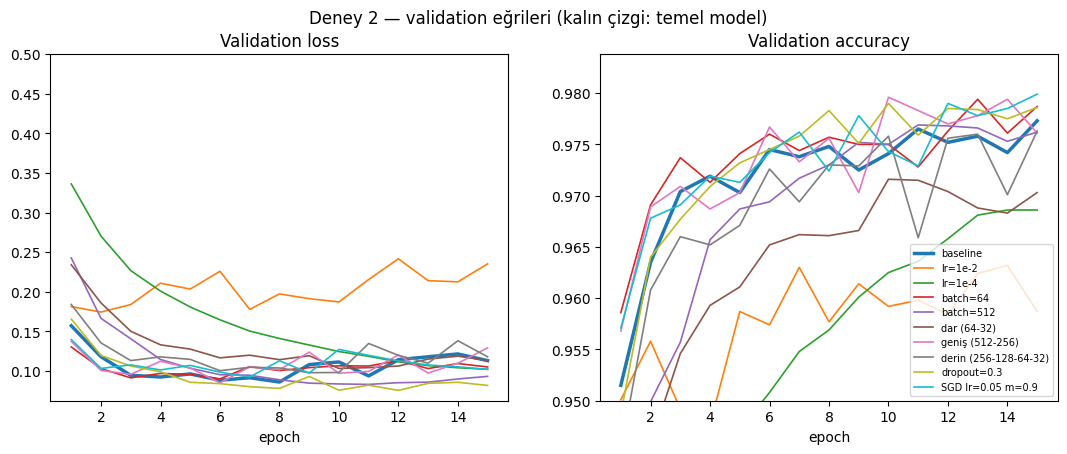

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for name, r in runs.items():
    ep = range(1, EPOCHS + 1)
    lw = 2.5 if name == "baseline" else 1.2
    ax[0].plot(ep, r["hist"]["val_loss"], label=name, lw=lw)
    ax[1].plot(ep, r["hist"]["val_acc"], label=name, lw=lw)
ax[0].set_title("Validation loss"); ax[0].set_xlabel("epoch"); ax[0].set_ylim(top=0.5)
ax[1].set_title("Validation accuracy"); ax[1].set_xlabel("epoch"); ax[1].set_ylim(bottom=0.95)
ax[1].legend(fontsize=7, loc="lower right")
fig.suptitle("Deney 2 — validation eğrileri (kalın çizgi: temel model)")
savefig("deney2_validation_egrileri"); plt.show()

## 4. Model seçimi (yalnızca validation ile)

En yüksek validation accuracy'ye sahip konfigürasyon **final model** olarak seçilir. Test kümesine bu noktaya kadar hiç dokunulmadı.

In [ ]:
best_name = results.loc[0, "deney"]
print("Seçilen final model:", best_name)
print(results.loc[0, ["hidden", "optimizer", "lr", "batch", "dropout", "val_acc"]].to_string())

Seçilen final model: SGD lr=0.05 m=0.9
hidden       256-128
optimizer        sgd
lr              0.05
batch            128
dropout          0.0
val_acc       0.9799


## 5. Final test değerlendirmesi

Test kümesi burada, seçim bittikten sonra **bir kez** kullanılır: temel model (Deney 1) ve seçilen final model için. Bu sonuçlara bakarak hiçbir şey değiştirilmez.

In [ ]:
def load_model(run):
    m = make_mlp(run["cfg"]["hidden"], run["cfg"]["dropout"]).to(device)
    m.load_state_dict(run["state"])
    return m.eval()

final_rows = []
for label, name in [("Deney 1 (temel)", "baseline"), (f"Final ({best_name})", best_name)]:
    tl, ta = evaluate(load_model(runs[name]), X_test, y_test)
    h = runs[name]["hist"]
    final_rows.append({"model": label, "train acc": h["train_acc"][-1], "val acc": h["val_acc"][-1],
                       "TEST loss": tl, "TEST acc": ta, "eğitim süresi (s)": runs[name]["time"]})
final = pd.DataFrame(final_rows).set_index("model")
final.to_csv("results/final_test.csv")
final.round(4)

,train acc,val acc,TEST loss,TEST acc,eğitim süresi (s)
model,,,,,
Deney 1 (temel),0.9984,0.9773,0.0931,0.9802,8.8068
Final (SGD lr=0.05 m=0.9),1.0000,0.9799,0.0882,0.9829,7.3812


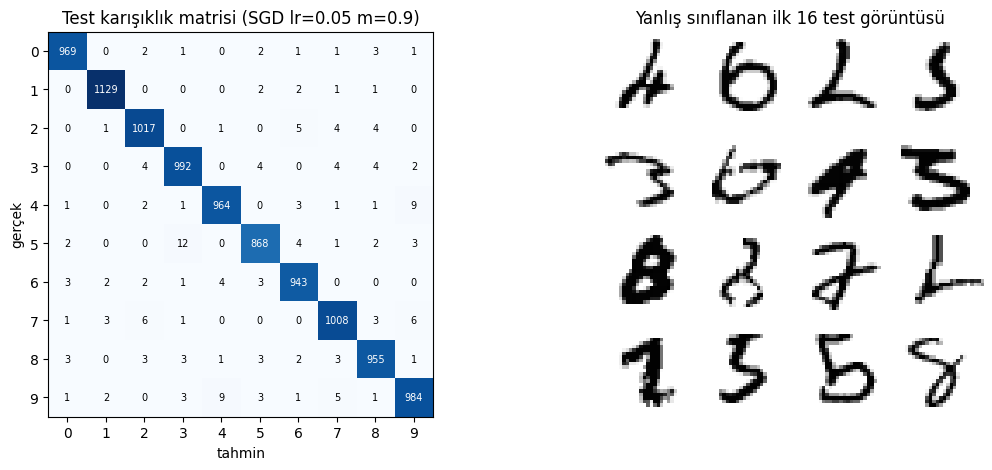

Yanlış sınıflanan test görüntüsü: 171 / 10000


In [ ]:
best_model = load_model(runs[best_name])
torch.save(runs[best_name]["state"], "results/final_mlp.pt")

with torch.no_grad():
    test_pred = best_model(X_test).argmax(1).cpu()
yt = y_test.cpu()
cm = torch.zeros(10, 10, dtype=torch.long)
for t, p in zip(yt, test_pred):
    cm[t, p] += 1

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].imshow(cm, cmap="Blues")
for i in range(10):
    for j in range(10):
        ax[0].text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=7,
                   color="white" if cm[i, j] > cm.max() / 2 else "black")
ax[0].set_xticks(range(10)); ax[0].set_yticks(range(10))
ax[0].set_xlabel("tahmin"); ax[0].set_ylabel("gerçek"); ax[0].set_title(f"Test karışıklık matrisi ({best_name})")

wrong = (test_pred != yt).nonzero().flatten()[:16]
grid = np.ones((4 * 28, 4 * 28))
for k, idx in enumerate(wrong):
    r, c = divmod(k, 4)
    grid[r*28:(r+1)*28, c*28:(c+1)*28] = 1 - X_test_raw[idx].numpy()
ax[1].imshow(grid, cmap="gray"); ax[1].axis("off")
ax[1].set_title("Yanlış sınıflanan ilk 16 test görüntüsü")
savefig("final_test_analiz"); plt.show()
print("Yanlış sınıflanan test görüntüsü:", int((test_pred != yt).sum()), "/ 10000")

## 6. Kendi el yazımla okul numaram

**Hazırlık:** Okul numaramın (`STUDENT_NUMBER`) her hanesini **kendim, trackpad ile** çizdim: `tools/draw_digits.py` yerel bir çizim tahtası açar; her rakamı ayrı ayrı elimle çizip kaydediyorum ve görüntüler `my_digits/01.png`, `02.png`, … (soldan sağa) olarak yazılıyor. Yani görüntüler kâğıt-kalem değil, trackpad ile oluşturulmuş el çizimleridir; yine de benim el hareketimle üretildi, internetten alınmadı.

**Görüntü hazırlama adımları (ödevin istediği gibi MNIST'e benzetme):**
1. Gri tonlamaya çevir.
2. Kontrastı `[0,1]` aralığına ger.
3. MNIST'te zemin siyah, rakam beyazdır; fotoğraf/tarama gibi açık zeminli görüntüler tersidir → gerekirse **renkleri ters çevir** (çizim tahtası zaten siyah zemin üstüne beyaz üretir).
4. Rakamın etrafını kırp, en-boy oranını bozmadan uzun kenarı 20 piksele ölçekle, 28×28 tuvalin ortasına koy, ardından **kütle merkezini** tuvalin merkezine kaydır (MNIST'in kendi hazırlama yöntemi bu).
5. **Normalizasyon:** eğitimde kullanılan train ortalaması/std ile standartlaştır.

Karşılaştırma için "MNIST'e benzetilmemiş" (yalnızca 28×28'e küçültülmüş) sürümü de tahmin ettiriyorum; fark, gerçek dünya verisinin eğitim verisinden ne kadar ayrıştığını (**distribution shift**) gösteriyor.

In [ ]:
STUDENT_NUMBER = "23120205056"
DIGIT_DIR = "my_digits"

def to_mnist(path, mnist_style=True):
    a = np.asarray(Image.open(path).convert("L"), dtype=np.float32)
    a = (a - a.min()) / max(a.max() - a.min(), 1e-6)         # kontrast germe -> [0,1]
    if np.median(a) > 0.5:                                    # açık zemin üstüne koyu rakam -> MNIST yönü
        a = 1.0 - a
    if not mnist_style:                                       # yalnızca 28x28'e küçült
        im = Image.fromarray((a * 255).astype(np.uint8)).resize((28, 28), Image.LANCZOS)
        return np.asarray(im, dtype=np.float32) / 255
    ys, xs = np.where(a > 0.5)                                # rakamın sınırlayıcı kutusu
    a = a[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    h, w = a.shape
    s = 20 / max(h, w)                                        # uzun kenar 20 px
    im = Image.fromarray((a * 255).astype(np.uint8)).resize((max(1, round(w * s)), max(1, round(h * s))), Image.LANCZOS)
    nh, nw = im.size[1], im.size[0]
    canvas = np.zeros((28, 28), dtype=np.float32)
    top, left = (28 - nh) // 2, (28 - nw) // 2
    canvas[top:top + nh, left:left + nw] = np.asarray(im, dtype=np.float32) / 255
    tot = canvas.sum()                                        # kütle merkezini ortala (kenar boşluğu >= 4 px, taşma olmaz)
    cy = (canvas.sum(1) * np.arange(28)).sum() / tot
    cx = (canvas.sum(0) * np.arange(28)).sum() / tot
    return np.roll(np.roll(canvas, round(13.5 - cy), axis=0), round(13.5 - cx), axis=1)

files = sorted(glob.glob(f"{DIGIT_DIR}/*.png") + glob.glob(f"{DIGIT_DIR}/*.jpg") + glob.glob(f"{DIGIT_DIR}/*.jpeg"))
assert STUDENT_NUMBER.isdigit(), "STUDENT_NUMBER'ı okul numaranla doldur (yalnızca rakamlar)."
assert len(files) == len(STUDENT_NUMBER), (
    f"{DIGIT_DIR}/ içinde {len(files)} görüntü var ama numara {len(STUDENT_NUMBER)} haneli; "
    "her hane için bir dosya (01.png, 02.png, ...) gerekli.")

true_labels = [int(c) for c in STUDENT_NUMBER]
own_mnist = np.stack([to_mnist(f, True) for f in files])
own_plain = np.stack([to_mnist(f, False) for f in files])
print(len(files), "görüntü hazırlandı:", STUDENT_NUMBER)

11 görüntü hazırlandı: 23120205056


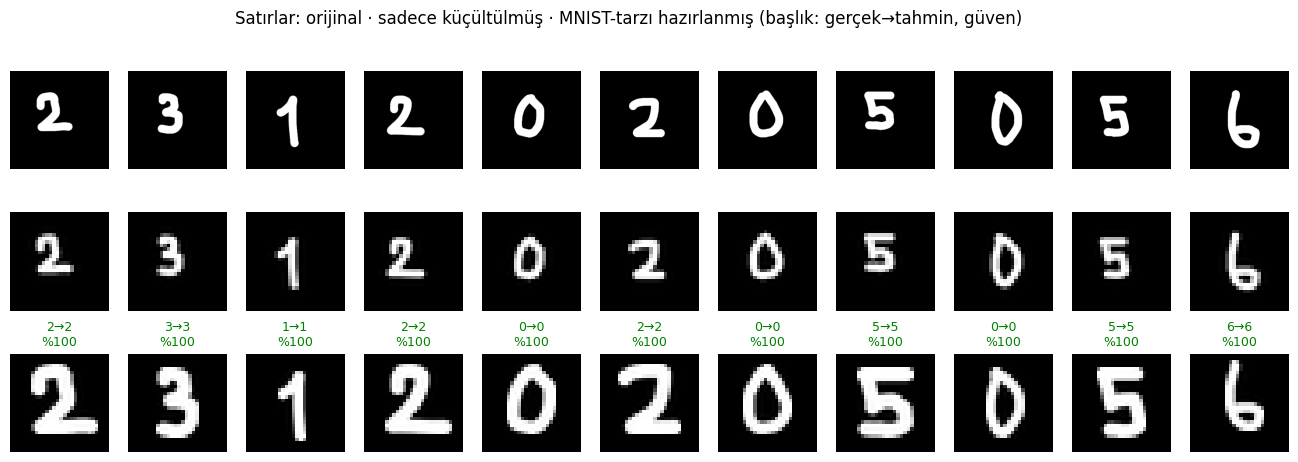

Kendi el yazım — MNIST-tarzı hazırlık: 100% (11/11) | sadece küçültme: 45%


,hane,gerçek,tahmin (MNIST-tarzı),güven,tahmin (sadece küçültülmüş)
0,1,2,2,1.000,3
1,2,3,3,1.000,3
2,3,1,1,0.999,1
3,4,2,2,1.000,5
4,5,0,0,1.000,9
5,6,2,2,1.000,2
6,7,0,0,1.000,9
7,8,5,5,1.000,9
8,9,0,0,1.000,0
9,10,5,5,1.000,2


In [ ]:
def predict(imgs):
    x = prep(torch.tensor(imgs)).to(device)
    with torch.no_grad():
        p = F.softmax(best_model(x), dim=1).cpu()
    return p.argmax(1).numpy(), p.max(1).values.numpy()

pred_m, conf_m = predict(own_mnist)
pred_p, conf_p = predict(own_plain)

n = len(files)
fig, axes = plt.subplots(3, n, figsize=(1.5 * n, 5.2), squeeze=False)
for i in range(n):
    axes[0, i].imshow(Image.open(files[i]).convert("L"), cmap="gray"); axes[0, i].axis("off")
    axes[1, i].imshow(own_plain[i], cmap="gray"); axes[1, i].axis("off")
    axes[2, i].imshow(own_mnist[i], cmap="gray"); axes[2, i].axis("off")
    ok = pred_m[i] == true_labels[i]
    axes[2, i].set_title(f"{true_labels[i]}→{pred_m[i]}\n%{conf_m[i]*100:.0f}", fontsize=9, color="green" if ok else "red")
axes[0, 0].set_ylabel("orijinal"); axes[1, 0].set_ylabel("sadece 28×28")
fig.suptitle("Satırlar: orijinal · sadece küçültülmüş · MNIST-tarzı hazırlanmış (başlık: gerçek→tahmin, güven)")
savefig("kendi_el_yazim"); plt.show()

own = pd.DataFrame({"hane": range(1, n + 1), "gerçek": true_labels,
                    "tahmin (MNIST-tarzı)": pred_m, "güven": conf_m.round(3),
                    "tahmin (sadece küçültülmüş)": pred_p})
own.to_csv("results/kendi_el_yazim.csv", index=False)
acc_m = (pred_m == np.array(true_labels)).mean(); acc_p = (pred_p == np.array(true_labels)).mean()
print(f"Kendi el yazım — MNIST-tarzı hazırlık: {acc_m:.0%} ({int((pred_m == np.array(true_labels)).sum())}/{n}) | sadece küçültme: {acc_p:.0%}")
own

In [ ]:
# Distribution shift: MNIST test ile kendi görüntülerimin basit istatistikleri
def stats(imgs):
    imgs = np.asarray(imgs)
    return {"ortalama piksel": imgs.mean(), "mürekkep oranı (piksel>0.3)": (imgs > 0.3).mean()}

shift = pd.DataFrame({"MNIST test": stats(X_test_raw.numpy()),
                      "kendi (MNIST-tarzı)": stats(own_mnist),
                      "kendi (sadece küçültülmüş)": stats(own_plain)}).T
shift.round(4)

,ortalama piksel,mürekkep oranı (piksel>0.3)
MNIST test,0.1325,0.1528
kendi (MNIST-tarzı),0.1907,0.2079
kendi (sadece küçültülmüş),0.0729,0.0841


## 7. Özet ve değerlendirme

In [ ]:
b = runs["baseline"]; fb = runs[best_name]
print(f"Deney 1 (temel MLP): train acc {b['hist']['train_acc'][-1]:.4f}, val acc {b['hist']['val_acc'][-1]:.4f}, "
      f"test acc {final.loc['Deney 1 (temel)', 'TEST acc']:.4f}, süre {b['time']:.1f} s")
print(f"Seçilen final model ({best_name}): val acc {fb['hist']['val_acc'][-1]:.4f}, "
      f"test acc {final.iloc[1]['TEST acc']:.4f}")
worst = results.iloc[-1]
print(f"En düşük validation accuracy: {worst['deney']} ({worst['val_acc']:.4f})")
if "acc_m" in globals():
    print(f"Kendi el yazım (okul numarası): MNIST-tarzı hazırlıkla {acc_m:.0%}, sadece küçültmeyle {acc_p:.0%} doğru.")
else:
    print("Kendi el yazım bölümü (§6) henüz çalıştırılmadı.")

Deney 1 (temel MLP): train acc 0.9984, val acc 0.9773, test acc 0.9802, süre 8.8 s
Seçilen final model (SGD lr=0.05 m=0.9): val acc 0.9799, test acc 0.9829
En düşük validation accuracy: lr=1e-2 (0.9587)
Kendi el yazım (okul numarası): MNIST-tarzı hazırlıkla 100%, sadece küçültmeyle 45% doğru.


### Genel değerlendirme

Tüm sayılar yukarıdaki çıktılardan; tek tohum (`SEED=42`) ve tek koşu olduğu için küçük farkları (aşağıda belirttim) kesin üstünlük olarak okumuyorum.

**Temel model (Deney 1).** 784-256-128-10 MLP, 15 epoch sonunda train accuracy %99,84, validation accuracy %97,73, **test accuracy %98,02** (8,8 s, GPU). Train accuracy neredeyse %100'e çıkarken validation %97,3–97,7 aralığında düzleşiyor ve validation loss 8. epoch'taki en düşük değerinden (0,086) sonra yükselip 0,113'e çıkıyor; yani loss açısından hafif bir **overfitting** var, ama accuracy düşmüyor. Validation ve test accuracy birbirine yakın (%97,73 / %98,02); seçim süreci test'e sızmadığı için bu beklenen bir şey.

**Hipotezlerim tuttu mu?**

- **Öğrenme oranı: tuttu.** Adam `lr=1e-2` en kötü sonuç (val acc %95,87, val loss 0,235; train loss de 0,086 ile en yüksekler arasında, yani adım çok büyük kalıyor). `lr=1e-4` aynı 15 epoch'ta yetersiz kaldı (train loss 0,050, val acc %96,86). `1e-3` ikisinin arasında iyi bir denge.
- **Batch size: kısmen tuttu.** `batch=512` 2,0 s'de bitti (temel 8,8 s), `batch=64` ise 16,6 s sürdü; yani küçük batch daha çok güncelleme ve daha uzun süre demek. Doğruluk farkı küçük (%97,87 / %97,73 / %97,62), bunun gürültü sınırı içinde olduğunu düşünüyorum.
- **Genişlik / derinlik: tutmadı.** Daha geniş (512-256) ve daha derin (256-128-64-32) ağlar validation'da kazanç getirmedi (%97,61 ve %97,63, temel %97,73); temel model zaten train'de ~%100'e ulaşıyor, kapasite darboğaz değil. Yalnızca çok dar ağ (64-32) belirgin kötü (%97,03, train–val farkı en büyük: 2,5 puan).
- **Dropout: tuttu.** `dropout=0.3` ile train accuracy biraz düştü (%99,66, temel %99,84), train–val farkı küçüldü (1,80 / 2,11 puan) ve **en düşük validation loss** bu modelde (0,082).
- **SGD + momentum: tutmadı.** Beklentim Adam'dan yavaş yakınsamasıydı; `lr=0.05, momentum=0.9` ise bu deneylerdeki en yüksek validation accuracy'yi (%97,99) verdi ve train accuracy'yi %100'e (train loss 0,0003) çıkardı. Bu ayarla SGD, 15 epoch'ta Adam'dan geri kalmadı; hipotezim yanlıştı.

**Hangi konfigürasyon seçildi, neden?** Seçim yalnızca validation accuracy'ye göre yapıldı: **SGD, lr=0.05, momentum=0.9** (256-128, batch 128). Test'te %98,29 (test loss 0,088) verdi; temel model %98,02. Üst sıradaki dört model (SGD, batch=64, dropout=0.3, temel) validation'da yalnızca 0,26 puan arayla (%97,73–97,99) sıralanıyor. 10 000 örnekte tek bir accuracy değerinin standart hatası yaklaşık 0,14 puan olduğundan bu fark anlamlı değil; SGD'nin seçilmesi büyük ölçüde bir "en yüksek sayı" seçimi. Daha sağlam bir karşılaştırma için birkaç farklı tohumla tekrar gerekirdi. Test'te 10 000 görüntüden 171'i yanlış sınıflandı.

**Kendi el yazımda sonuç ve distribution shift.** Okul numaramın 11 hanesini trackpad ile çizdim. MNIST-tarzı hazırlıkla (kırp, 20 px'e ölçekle, kütle merkezini ortala, normalize et) **11/11 doğru**, güven ≥ 0,999. Aynı çizimleri yalnızca 28×28'e küçültünce **5/11 doğru (%45)**; yanlışlar 2→3, 2→5, 0→9, 0→9, 5→9, 5→2. Model değişmedi, yalnızca girdinin hazırlanışı değişti. Yani MNIST'te elde edilen %98 doğruluk, girdinin MNIST'in dağılımına (boyut, konum, ortalanmış rakam) uyduğu varsayımına bağlı; bu varsayım bozulunca doğruluk ciddi düşüyor. İstatistik tablosu bunu destekliyor: sadece küçültülmüş görüntülerde ortalama piksel 0,073 ve mürekkep oranı 0,084 ile MNIST test'in (0,133 / 0,153) çok altında (rakam tuvalde küçük kalıyor, çizgiler inceliyor); MNIST-tarzı hazırlıkta ise 0,191 / 0,208 ile MNIST'in biraz üstünde (trackpad çizgilerim MNIST'inkinden daha kalın). Hangi etkinin tek başına hatalara yol açtığını ayrıca denemedim; yukarıdaki açıklama, rakamların küçük ve ortalanmamış olması yönünde bir yorum.

**Sınırlar.** (1) Tek tohum, tek koşu; küçük farklar kesin değil. (2) Kendi el yazım yalnızca 11 görüntü ve tek kişi; %100 sonucu, gerçek dünya doğruluğunun istatistiksel olarak güvenilir bir ölçüsü değil. (3) Görüntüler kâğıt-kalem değil trackpad çizimi ve siyah zeminde; fotoğraf gürültüsü, aydınlatma ve kâğıt dokusu bu denemede yok. (4) MLP görüntüyü 784 uzunluklu vektör olarak aldığı için kaydırma/ölçek değişimine duyarlı; CNN bu ödevde kullanılmadı.